<a href="https://colab.research.google.com/github/RiyaSunil28/nitinternship/blob/main/Week4_nit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q open_clip_torch ftfy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 34.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.2 MB/s eta 0:00:00


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import open_clip

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from torchvision import datasets
from torch.utils.data import DataLoader, Subset

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)

Using device: cuda


In [ ]:
model, _, preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32",
    pretrained="openai"
)

tokenizer = open_clip.get_tokenizer("ViT-B-32")

model = model.to(device)
model.eval()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


open_clip_model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


CLIP(
  (visual): VisionTransformer(
    (conv1): Conv2d(3, 768, kernel_size=(32, 32), stride=(32, 32), bias=False)
    (patch_dropout): Identity()
    (ln_pre): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
    (transformer): Transformer(
      (resblocks): ModuleList(
        (0-11): 12 x ResidualAttentionBlock(
          (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
          )
          (ls_1): Identity()
          (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (mlp): Sequential(
            (c_fc): Linear(in_features=768, out_features=3072, bias=True)
            (gelu): GELU(approximate='none')
            (c_proj): Linear(in_features=3072, out_features=768, bias=True)
          )
          (ls_2): Identity()
        )
      )
    )
    (ln_post): LayerNorm((768,), eps=1e-05, elementwise_affine

In [ ]:
for param in model.parameters():
    param.requires_grad = False

In [ ]:
print(sum(p.requires_grad for p in model.parameters()))

0


In [ ]:
train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=preprocess
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=preprocess
)

100%|██████████| 170M/170M [00:24<00:00, 6.93MB/s]


In [ ]:
class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

known_classes = [0, 1, 3, 5, 7]

known_names = [class_names[i] for i in known_classes]

In [ ]:
train_indices = [
    i for i, (_, label) in enumerate(train_dataset)
    if label in known_classes
]

test_indices = [
    i for i, (_, label) in enumerate(test_dataset)
    if label in known_classes
]

train_subset = Subset(train_dataset, train_indices)
test_subset = Subset(test_dataset, test_indices)

In [ ]:
train_loader = DataLoader(
    train_subset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_subset,
    batch_size=64,
    shuffle=False
)

In [ ]:
prompts = [
    f"a photo of a {name}"
    for name in known_names
]

print(prompts)

['a photo of a airplane', 'a photo of a automobile', 'a photo of a cat', 'a photo of a dog', 'a photo of a horse']


In [ ]:
text_tokens = tokenizer(prompts).to(device)

with torch.no_grad():

    text_features = model.encode_text(text_tokens)

    text_features = text_features / text_features.norm(
        dim=-1,
        keepdim=True
    )

In [ ]:
feature_dim = text_features.shape[1]

prompt_vectors = nn.Parameter(
    torch.randn(
        len(known_classes),
        feature_dim,
        device=device
    ) * 0.01
)

In [ ]:
print(prompt_vectors.shape)

torch.Size([5, 512])


In [ ]:
optimizer = optim.Adam(
    [prompt_vectors],
    lr=1e-3
)

criterion = nn.CrossEntropyLoss()

In [ ]:
loss_history = []

for epoch in range(5):

    epoch_loss = 0

    for images, labels in train_loader:

        images = images.to(device)

        labels = torch.tensor([
            known_classes.index(label.item())
            for label in labels
        ]).to(device)

        with torch.no_grad():

            image_features = model.encode_image(images)

            image_features = image_features / image_features.norm(
                dim=-1,
                keepdim=True
            )

        adapted_text = text_features + prompt_vectors

        adapted_text = adapted_text / adapted_text.norm(
            dim=-1,
            keepdim=True
        )

        logits = image_features @ adapted_text.T

        loss = criterion(logits, labels)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)

    loss_history.append(avg_loss)

    print(f"Epoch {epoch+1}/5 - Loss: {avg_loss:.4f}")

Epoch 1/5 - Loss: 1.3978
Epoch 2/5 - Loss: 1.3567
Epoch 3/5 - Loss: 1.3531
Epoch 4/5 - Loss: 1.3527
Epoch 5/5 - Loss: 1.3527


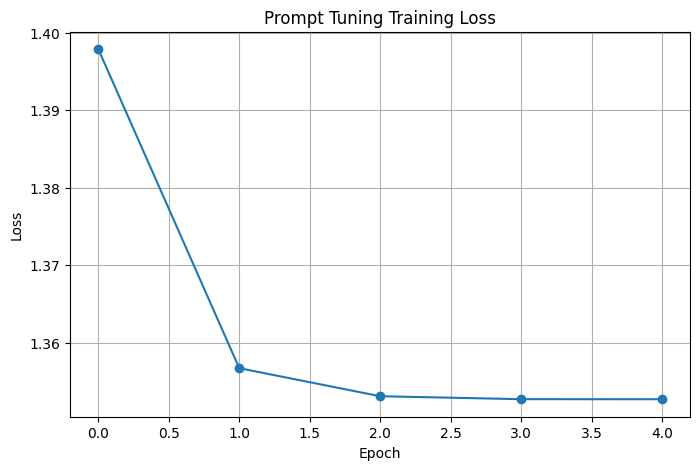

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history, marker="o")

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("Prompt Tuning Training Loss")

plt.grid(True)

plt.show()

In [ ]:
def evaluate(text_repr):

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)

            labels = torch.tensor([
                known_classes.index(label.item())
                for label in labels
            ]).to(device)

            image_features = model.encode_image(images)

            image_features = image_features / image_features.norm(
                dim=-1,
                keepdim=True
            )

            logits = image_features @ text_repr.T

            predictions = logits.argmax(dim=1)

            correct += (predictions == labels).sum().item()

            total += labels.size(0)

    return 100 * correct / total

In [ ]:
base_text = text_features

tuned_text = text_features + prompt_vectors

tuned_text = tuned_text / tuned_text.norm(
    dim=-1,
    keepdim=True
)

zero_shot_accuracy = evaluate(base_text)

prompt_accuracy = evaluate(tuned_text)

print(f"Zero-shot CLIP Accuracy: {zero_shot_accuracy:.2f}%")

print(f"Prompt-Tuned CLIP Accuracy: {prompt_accuracy:.2f}%")

Zero-shot CLIP Accuracy: 92.38%
Prompt-Tuned CLIP Accuracy: 93.54%


In [ ]:
results = pd.DataFrame({

    "Model": [
        "CLIP Zero-Shot",
        "Prompt-Tuned CLIP"
    ],

    "Accuracy (%)": [
        round(zero_shot_accuracy, 2),
        round(prompt_accuracy, 2)
    ]
})

results

,Model,Accuracy (%)
0,CLIP Zero-Shot,92.38
1,Prompt-Tuned CLIP,93.54
